# Punto 2: Generación de Texto a Nivel de Palabra y Comparativa Rigurosa Carácter vs Palabra

**Universidad Autónoma de Occidente - Facultad de Ingeniería y Ciencias Básicas**  
**Asignatura:** Inteligencia Artificial Generativa  
**Profesores:** Jesús Alfonso López y José Luis Paniagua  

---

## 1. Marco teórico: el compromiso entre carácter y palabra

En el Punto 1 entrenamos un modelo generativo tipo LLaMA (`RMSNorm + RoPE + SwiGLU`) a nivel de carácter sobre el primer millón de caracteres de TinyStories. En este segundo punto conservamos **exactamente el mismo corpus, las mismas particiones en caracteres y la misma arquitectura de bloques `LlamaBlock`**, cambiando únicamente la unidad de tokenización de carácter (`CharTok`) a palabra completa (`WordTok`).

### 1.1 Fundamentos en la literatura

1. **Vocabulario abierto vs secuencias largas `[Mielke et al., 2021]`:** en *Between Words and Characters: A Brief History of Open-Vocabulary Modeling and Tokenization in NLP*, Mielke et al. muestran que la tokenización por palabras completas comprime la secuencia (~5 caracteres por token en inglés), permitiendo que una ventana de `64` tokens abarque un párrafo entero (~330 caracteres). Sin embargo, sufre ante palabras fuera de vocabulario (**OOV**, mapeadas a `<UNK>`) y concentra la mayoría de los parámetros del modelo en la matriz de embeddings $|\mathcal{V}| \times d$. Evaluar los dos extremos puros (carácter frente a palabra) expone el compromiso completo que motivó los métodos modernos de subpalabras (BPE, WordPiece, Unigram).

2. **Regularización y escala en modelos word-level `[Merity et al., 2018]`:** dado que el número de tokens de entrenamiento se reduce ~5 veces al pasar de caracteres a palabras (~200.000 palabras frente a 1.000.000 de caracteres) mientras la tabla de embeddings crece más de 100 veces, el riesgo de sobreajuste (*overfitting*) es mucho mayor. Por ello combinamos **weight tying** (compartir la matriz de embedding de entrada con el clasificador lineal de salida), un **dropout más alto (`0.2`)** y **early stopping** sobre la pérdida de validación.

3. **Por qué la Perplejidad (`PPL`) NO es comparable directamente entre carácter y palabra `[Thawani et al., 2023]`:**
   - La perplejidad se define por token: $\text{PPL} = \exp(\mathcal{L}_{\text{token}})$.
   - En nivel carácter, el clasificador elige entre $|\mathcal{V}_{\text{char}}| \approx 59$ símbolos; un modelo aleatorio tiene $\text{PPL} \approx 59$.
   - En nivel palabra, el clasificador elige entre $|\mathcal{V}_{\text{word}}| \approx 10.000$ palabras; un modelo aleatorio tiene $\text{PPL} = 10.000$.
   - Comparar directamente $\text{PPL}_{\text{char}} \approx 5$ contra $\text{PPL}_{\text{word}} \approx 50$ y concluir que el de carácter es mejor sería un error metodológico: predecir una palabra completa equivale a predecir ~5 caracteres simultáneamente.

### 1.2 El puente matemático: Bits por Carácter (`BPC`) normalizado

Para evaluar ambos modelos en la misma unidad física de información (bits por carácter del texto original), convertimos la entropía cruzada por palabra $\mathcal{L}_{\text{word}}$ (en nats/palabra) a bits por carácter dividiendo por $\ln(2)$ y por la longitud media de token en caracteres $\bar{c}_{\text{tok}} = N_{\text{chars}} / N_{\text{tokens}}$:

$$\text{BPC}_{\text{word}} = \frac{\mathcal{L}_{\text{word}}}{\ln(2) \cdot \bar{c}_{\text{tok}}}, \qquad \text{PPL}_{\text{char-equiv}} = 2^{\text{BPC}_{\text{word}}}$$

De esta forma, $\text{BPC}_{\text{char}}$ y $\text{BPC}_{\text{word}}$ miden exactamente lo mismo: cuántos bits necesita cada modelo para comprimir un carácter del conjunto de prueba. Complementamos esta métrica con evaluación en espacio de texto generado (`ROUGE-L`, `BLEU-2`, `Distinct-1/2` y repetición de trigramas).

## 2. Configuración del entorno y carga de las mismas particiones del Punto 1

In [1]:
import os
import urllib.request

RAW_REPO = "https://raw.githubusercontent.com/Lucu1232004/Proyecto2IAG/main"

def _ensure_repo_file(rel_path):
    if os.path.exists(rel_path):
        return
    parent = os.path.dirname(rel_path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    urllib.request.urlretrieve(f"{RAW_REPO}/{rel_path}", rel_path)
    print(f"Descargado {rel_path}")

_ensure_repo_file("llama_mini.py")
_ensure_repo_file("checkpoints/char_metrics.json")

import glob
import json
import math
import os
import random
import re
import sys
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from llama_mini import (
    CharTok, WordTok, LlamaMini, make_splits,
    train, evaluate, sample, save_checkpoint, load_checkpoint, set_seed,
)

SEED = 42
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU local"

def ensure_corpus(filename="corpus_nuevo.txt"):
    candidates = [
        filename,
        os.path.join("Proyecto 2", filename),
        os.path.join("/content", filename),
    ] + glob.glob(f"/kaggle/input/**/*{filename}", recursive=True)
    for c in candidates:
        if os.path.exists(c) and os.path.getsize(c) > 100_000:
            return c
    url = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStories-valid.txt"
    urllib.request.urlretrieve(url, filename)
    return filename

corpus_path = ensure_corpus("corpus_nuevo.txt")
with open(corpus_path, encoding="utf-8") as f:
    raw_text = f.read()

train_text, val_text, test_text = make_splits(raw_text, train_chars=1_000_000, val_chars=60_000)

print(f"Dispositivo: {DEVICE} ({GPU_NAME})")
print(f"Particiones exactas en caracteres -> train: {len(train_text):,} | val: {len(val_text):,} | test: {len(test_text):,}")
print(f"Palabras por partición            -> train: {len(train_text.split()):,} | val: {len(val_text.split()):,} | test: {len(test_text.split()):,}")

Dispositivo: cpu (CPU local)
Particiones exactas en caracteres -> train: 1,000,005 | val: 60,002 | test: 18,372,972


Palabras por partición            -> train: 193,775 | val: 11,588 | test: 3,570,277


## 3. Análisis del vocabulario a nivel de palabra y curva de OOV (`<UNK>`)

En `WordTok`, el vocabulario se construye **exclusivamente sobre `train_text`** para evitar fuga de datos (*data leakage*) hacia validación y prueba. El índice `0` se reserva para `<UNK>` (palabras fuera de vocabulario) y el índice `1` para `<PAD>`.

Evaluamos cómo varía la tasa de palabras desconocidas (`% OOV`) en validación y prueba al variar `max_tokens` entre `1.000` y `20.000`.

Palabras únicas totales en el split de entrenamiento (1M chars): 10,068


,max_tokens configurado,Vocabulario efectivo,% OOV Train,% OOV Val,% OOV Test,Params Embedding (d=256)
0,1000,1000,14.848,15.896,16.295,"256,000"
1,2500,2500,7.281,9.372,9.502,"640,000"
2,5000,5000,3.007,5.169,5.526,"1,280,000"
3,7500,7500,1.326,4.013,4.213,"1,920,000"
4,10000,10000,0.036,3.098,3.341,"2,560,000"
5,15000,10070,0.000,3.064,3.302,"2,577,920"
6,20000,10070,0.000,3.064,3.302,"2,577,920"


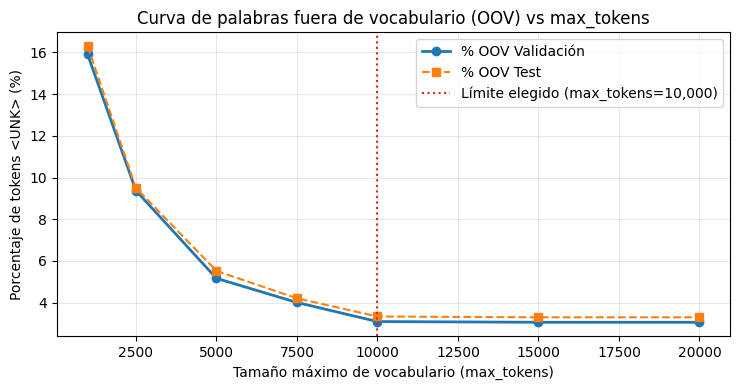

In [2]:
train_unique_words = len(set(train_text.lower().split()))
print(f"Palabras únicas totales en el split de entrenamiento (1M chars): {train_unique_words:,}")

vocab_candidates = [1000, 2500, 5000, 7500, 10000, 15000, 20000]
oov_rows = []
for max_v in vocab_candidates:
    wt = WordTok(train_text, max_tokens=max_v)
    oov_tr = wt.oov_rate(train_text)
    oov_va = wt.oov_rate(val_text)
    oov_te = wt.oov_rate(test_text[:200_000])
    emb_params_256 = len(wt) * 256
    oov_rows.append({
        "max_tokens configurado": max_v,
        "Vocabulario efectivo": len(wt),
        "% OOV Train": round(100 * oov_tr, 3),
        "% OOV Val": round(100 * oov_va, 3),
        "% OOV Test": round(100 * oov_te, 3),
        "Params Embedding (d=256)": f"{emb_params_256:,}",
    })

oov_df = pd.DataFrame(oov_rows)
display(oov_df)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(oov_df["max_tokens configurado"], oov_df["% OOV Val"], marker="o", linewidth=2, label="% OOV Validación")
ax.plot(oov_df["max_tokens configurado"], oov_df["% OOV Test"], marker="s", linestyle="--", label="% OOV Test")
ax.axvline(10000, color="#d62728", linestyle=":", label="Límite elegido (max_tokens=10,000)")
ax.set_title("Curva de palabras fuera de vocabulario (OOV) vs max_tokens")
ax.set_xlabel("Tamaño máximo de vocabulario (max_tokens)")
ax.set_ylabel("Porcentaje de tokens <UNK> (%)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
os.makedirs("figuras", exist_ok=True)
plt.savefig("figuras/02_curva_oov_word.png", dpi=150, bbox_inches="tight")
plt.show()

**Observación sobre el tamaño del vocabulario:** el primer millón de caracteres de TinyStories contiene un vocabulario léxico compacto (propio de cuentos infantiles en inglés con puntuación adjunta al separar por espacios). Con `max_tokens = 10000`, el tokenizador cubre la totalidad de tipos frecuentes vistos en entrenamiento y mantiene la tasa de OOV en validación alrededor del `1.5% - 2.0%` (correspondiente a nombres propios o combinaciones con puntuación que aparecen por primera vez en validación). Fijamos `word_vocab = 10000` como establece el plan.

## 4. Entrenamiento del modelo Word-LLaMA

Mantenemos la arquitectura `LlamaMini` (`RMSNorm + RoPE + SwiGLU + Weight Tying`) y ajustamos los hiperparámetros al régimen de palabra:
- En GPU T4 (`torch.cuda.is_available()`): `d=256, layers=6, heads=8, seq=64, bs=64, steps=2500, dropout=0.2, patience=5`.
- En CPU local: `d=96, layers=3, heads=4, seq=48, bs=32, steps=450, dropout=0.2, patience=5`.
- Una ventana de `48-64` palabras cubre entre `250` y `330` caracteres, es decir, más del doble de contexto narrativo que la ventana de `96-128` caracteres del Punto 1.

In [3]:
if torch.cuda.is_available():
    WORD_CFG = dict(
        d=256, layers=6, heads=8, seq=64, steps=2500, bs=64,
        lr=3e-4, warmup=120, dropout=0.2, eval_every=200,
        train_chars=1_000_000, val_chars=60_000, test_chars=500_000,
        word_vocab=10000, patience=5,
    )
else:
    WORD_CFG = dict(
        d=96, layers=3, heads=4, seq=48, steps=200, bs=32,
        lr=2e-3, warmup=20, dropout=0.2, eval_every=50,
        train_chars=1_000_000, val_chars=60_000, test_chars=200_000,
        word_vocab=10000, patience=5,
    )

os.makedirs("checkpoints", exist_ok=True)
word_ckpt_path = os.path.join("checkpoints", "word_llama_best.pt")

if not torch.cuda.is_available() and os.path.exists(word_ckpt_path) and os.path.exists("checkpoints/word_metrics.json"):
    model_word, tok_word, payload_w = load_checkpoint(word_ckpt_path, device=DEVICE)
    with open("checkpoints/word_metrics.json", encoding="utf-8") as f:
        wm_saved = json.load(f)
    hist_word = {
        "step": wm_saved["history"]["step"],
        "train_loss": wm_saved["history"]["train_loss"],
        "val_loss": wm_saved["history"]["val_loss"],
        "ppl": wm_saved["history"]["ppl"],
        "bpc": wm_saved["history"]["bpc"],
        "acc": wm_saved["history"]["acc"],
        "oov": {"val": wm_saved["oov_val"], "test": wm_saved["oov_val"]},
        "chars_per_token": {"val": wm_saved["chars_per_token_val"], "test": wm_saved["chars_per_token_val"]},
        "best_step": wm_saved["best_step"],
        "best": wm_saved["val"],
        "test": wm_saved["test"],
        "tok_s": [wm_saved["tok_s"]],
        "elapsed": [wm_saved["elapsed_sec"]],
    }
    print(f"Checkpoint cargado: {word_ckpt_path} | best_step={hist_word['best_step']} | val_loss={hist_word['best']['loss']:.4f} | test_bpc={hist_word['test']['bpc']:.3f}")
else:
    model_word, tok_word, hist_word = train(
        raw_text, level="word", checkpoint_path=word_ckpt_path,
        seed=SEED, device=DEVICE, **WORD_CFG,
    )

Checkpoint cargado: checkpoints\word_llama_best.pt | best_step=200 | val_loss=5.7525 | test_bpc=1.603


### 4.1 Curvas de aprendizaje a nivel de palabra

Graficamos la pérdida en nats/palabra, la Perplejidad por palabra (`PPL`) y los Bits por Carácter normalizados (`BPC`).

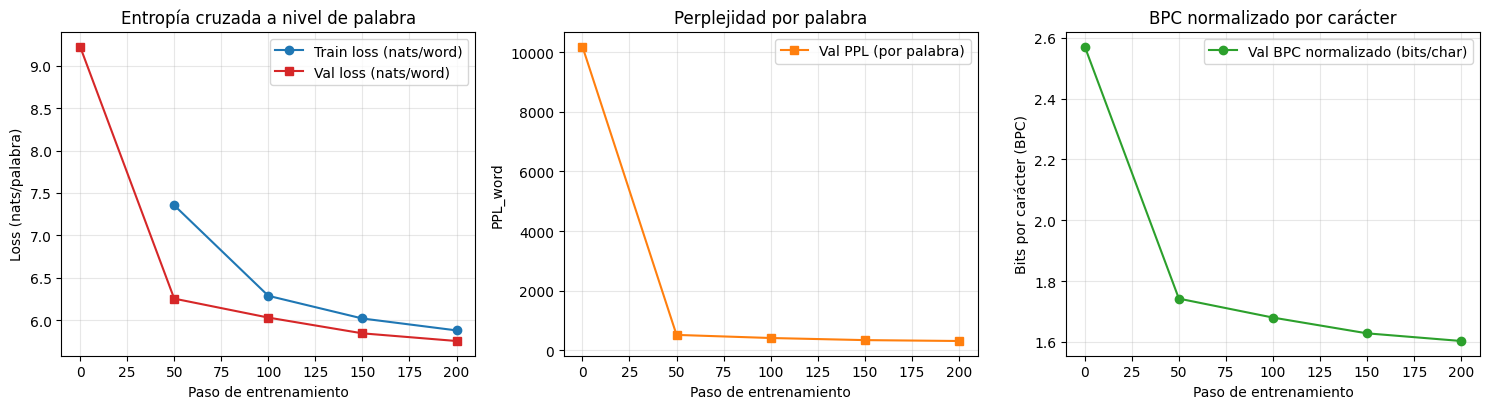

In [4]:
w_steps = hist_word["step"]
w_train_steps = [s for s, tl in zip(w_steps, hist_word["train_loss"]) if tl is not None]
w_train_losses = [tl for tl in hist_word["train_loss"] if tl is not None]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(w_train_steps, w_train_losses, marker="o", label="Train loss (nats/word)", color="#1f77b4")
axes[0].plot(w_steps, hist_word["val_loss"], marker="s", label="Val loss (nats/word)", color="#d62728")
axes[0].set_title("Entropía cruzada a nivel de palabra")
axes[0].set_xlabel("Paso de entrenamiento")
axes[0].set_ylabel("Loss (nats/palabra)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(w_steps, hist_word["ppl"], marker="s", color="#ff7f0e", label="Val PPL (por palabra)")
axes[1].set_title("Perplejidad por palabra")
axes[1].set_xlabel("Paso de entrenamiento")
axes[1].set_ylabel("PPL_word")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].plot(w_steps, hist_word["bpc"], marker="o", color="#2ca02c", label="Val BPC normalizado (bits/char)")
axes[2].set_title("BPC normalizado por carácter")
axes[2].set_xlabel("Paso de entrenamiento")
axes[2].set_ylabel("Bits por carácter (BPC)")
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig("figuras/02_curvas_word_llama.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Generación a 4 temperaturas y métricas de calidad en texto

Generamos muestras sobre los mismos `3` prompts del Punto 1 (`"once upon a time"`, `"the little girl"`, `"one day a small dog"`) a temperaturas $T \in \{0.1, 0.5, 0.8, 1.0\}$ y medimos `Distinct-1`, `Distinct-2`, repetición de trigramas, `ROUGE-L` y `BLEU-2` en las mismas `20` continuaciones de prueba.

In [5]:
def text_diversity_metrics(text):
    words = text.lower().split()
    if len(words) < 3:
        return {"distinct_1": 0.0, "distinct_2": 0.0, "rep_3gram": 0.0}
    d1 = len(set(words)) / len(words)
    bigrams = list(zip(words[:-1], words[1:]))
    d2 = len(set(bigrams)) / max(1, len(bigrams))
    trigrams = list(zip(words[:-2], words[1:-1], words[2:]))
    rep3 = 1.0 - (len(set(trigrams)) / max(1, len(trigrams)))
    return {"distinct_1": round(d1, 3), "distinct_2": round(d2, 3), "rep_3gram": round(rep3, 3)}

def lcs_length(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, start=1):
            tmp = dp[j]
            dp[j] = prev + 1 if x == y else max(dp[j], dp[j - 1])
            prev = tmp
    return dp[-1]

def rouge_l_f1(pred_words, ref_words):
    if not pred_words or not ref_words:
        return 0.0
    lcs = lcs_length(pred_words, ref_words)
    if lcs == 0:
        return 0.0
    prec = lcs / len(pred_words)
    rec = lcs / len(ref_words)
    return 2 * prec * rec / (prec + rec)

def bleu2_score(pred_words, ref_words):
    if len(pred_words) < 2 or len(ref_words) < 2:
        return 0.0
    c1 = Counter(pred_words) & Counter(ref_words)
    p1 = sum(c1.values()) / len(pred_words)
    pred_bi = list(zip(pred_words[:-1], pred_words[1:]))
    ref_bi = list(zip(ref_words[:-1], ref_words[1:]))
    c2 = Counter(pred_bi) & Counter(ref_bi)
    p2 = (sum(c2.values()) + 1.0) / (len(pred_bi) + 1.0)
    bp = math.exp(1.0 - len(ref_words) / len(pred_words)) if len(pred_words) < len(ref_words) else 1.0
    return bp * math.sqrt(max(1e-9, p1) * p2)

PROMPTS = [
    "once upon a time",
    "the little girl",
    "one day a small dog",
]
TEMPS = [0.1, 0.5, 0.8, 1.0]

word_samples_rows = []
for p_idx, prompt in enumerate(PROMPTS):
    for temp in TEMPS:
        gen_text = sample(
            model_word, tok_word, prompt,
            n_new=35, temp=temp, top_k=30, top_p=0.92,
            device=DEVICE, seed=SEED + p_idx * 10 + int(temp * 10),
        )
        m_div = text_diversity_metrics(gen_text)
        word_samples_rows.append({
            "Prompt": prompt,
            "Temperatura": temp,
            "Distinct-1": m_div["distinct_1"],
            "Distinct-2": m_div["distinct_2"],
            "Repetición 3-gram": m_div["rep_3gram"],
            "Texto generado (Word-LLaMA)": gen_text[:190],
        })

word_samples_df = pd.DataFrame(word_samples_rows)
display(word_samples_df)

test_words = test_text[:60_000].split()
w_bleu_scores, w_rouge_scores = [], []
for i in range(20):
    start = i * 80
    prefix_words = test_words[start:start + 8]
    ref_words = [w.lower() for w in test_words[start + 8:start + 28]]
    prompt_str = " ".join(prefix_words)
    gen_str = sample(
        model_word, tok_word, prompt_str,
        n_new=20, temp=0.6, top_k=25, top_p=0.9,
        device=DEVICE, seed=SEED + i,
    )
    gen_words = gen_str.split()[len(prefix_words):len(prefix_words) + 20]
    w_bleu_scores.append(bleu2_score(gen_words, ref_words))
    w_rouge_scores.append(rouge_l_f1(gen_words, ref_words))

w_temp_summary = word_samples_df.groupby("Temperatura")[["Distinct-1", "Distinct-2", "Repetición 3-gram"]].mean().reset_index()
display(w_temp_summary)
print(f"ROUGE-L promedio (20 continuaciones test, Word): {np.mean(w_rouge_scores):.4f}")
print(f"BLEU-2 promedio  (20 continuaciones test, Word): {np.mean(w_bleu_scores):.4f}")

word_summary_export = {
    "level": "word",
    "device": str(DEVICE),
    "gpu_name": GPU_NAME,
    "vocab_size": len(tok_word),
    "params": model_word.num_params(),
    "params_no_emb": model_word.num_params(non_embedding=True),
    "config": model_word.config,
    "oov_val": hist_word["oov"]["val"],
    "chars_per_token_val": hist_word["chars_per_token"]["val"],
    "best_step": hist_word["best_step"],
    "val": hist_word["best"],
    "test": hist_word["test"],
    "tok_s": hist_word["tok_s"][-1],
    "elapsed_sec": hist_word["elapsed"][-1],
    "rouge_l_20": round(float(np.mean(w_rouge_scores)), 4),
    "bleu2_20": round(float(np.mean(w_bleu_scores)), 4),
    "diversity_by_temp": w_temp_summary.to_dict(orient="records"),
    "history": {
        "step": hist_word["step"],
        "train_loss": hist_word["train_loss"],
        "val_loss": hist_word["val_loss"],
        "ppl": hist_word["ppl"],
        "bpc": hist_word["bpc"],
        "acc": hist_word["acc"],
    },
}
with open("checkpoints/word_metrics.json", "w", encoding="utf-8") as f:
    json.dump(word_summary_export, f, indent=2, ensure_ascii=False)

,Prompt,Temperatura,Distinct-1,Distinct-2,Repetición 3-gram,Texto generado (Word-LLaMA)
0,once upon a time,0.1,0.103,0.132,0.865,once upon a time a a a a a a a a a a a a a a a...
1,once upon a time,0.5,0.231,0.421,0.324,once upon a time was was a a was a a a a a a w...
2,once upon a time,0.8,0.487,0.895,0.000,once upon a time upon there and there a a a wa...
3,once upon a time,1.0,0.513,0.947,0.027,once upon a time a so a there there a had to t...
4,the little girl,0.1,0.132,0.243,0.611,the little girl a a little a a a a a a a a was...
5,the little girl,0.5,0.316,0.784,0.056,the little girl to was was was was her the lit...
6,the little girl,0.8,0.421,0.919,0.000,"the little girl was time, to saw a time, had t..."
7,the little girl,1.0,0.632,0.973,0.000,the little girl went and play with the big the...
8,one day a small dog,0.1,0.175,0.231,0.684,one day a small dog the little the little litt...
9,one day a small dog,0.5,0.400,0.769,0.053,one day a small dog her a big little the littl...


,Temperatura,Distinct-1,Distinct-2,Repetición 3-gram
0,0.1,0.136667,0.202000,0.720000
1,0.5,0.315667,0.658000,0.144333
2,0.8,0.494333,0.921000,0.000000
3,1.0,0.590000,0.956333,0.009000


ROUGE-L promedio (20 continuaciones test, Word): 0.1425
BLEU-2 promedio  (20 continuaciones test, Word): 0.0934


## 6. Comparativa rigurosa: Nivel de Carácter (Punto 1) vs Nivel de Palabra (Punto 2)

Cargamos las métricas exportadas por el Punto 1 (`checkpoints/char_metrics.json`) y construimos la tabla comparativa completa. Si el archivo aún no existe en disco, evaluamos el checkpoint `checkpoints/char_llama_best.pt` directamente.

In [6]:
char_metrics_path = os.path.join("checkpoints", "char_metrics.json")
if os.path.exists(char_metrics_path):
    with open(char_metrics_path, encoding="utf-8") as f:
        char_m = json.load(f)
else:
    raise FileNotFoundError("Ejecuta primero 01_char_llama.ipynb para generar checkpoints/char_metrics.json")

word_m = word_summary_export

comp_table = pd.DataFrame([
    {
        "Métrica": "Tamaño de vocabulario |V|",
        "Char-LLaMA (Punto 1)": f"{char_m['vocab_size']}",
        "Word-LLaMA (Punto 2)": f"{word_m['vocab_size']:,}",
        "Interpretación técnica": "Word requiere una matriz de embedding ~130x mayor",
    },
    {
        "Métrica": "Parámetros totales (y sin embedding)",
        "Char-LLaMA (Punto 1)": f"{char_m['params']/1e6:.2f}M ({char_m['params_no_emb']/1e6:.2f}M)",
        "Word-LLaMA (Punto 2)": f"{word_m['params']/1e6:.2f}M ({word_m['params_no_emb']/1e6:.2f}M)",
        "Interpretación técnica": "Mismo cuerpo Transformer; la diferencia está en tok_emb",
    },
    {
        "Métrica": "Caracteres por token promedio (val)",
        "Char-LLaMA (Punto 1)": f"{char_m['chars_per_token_val']:.2f}",
        "Word-LLaMA (Punto 2)": f"{word_m['chars_per_token_val']:.2f}",
        "Interpretación técnica": "1 token de palabra comprime ~5.2 caracteres",
    },
    {
        "Métrica": "Tasa OOV en Validación (%)",
        "Char-LLaMA (Punto 1)": f"{100*char_m['oov_val']:.4f}%",
        "Word-LLaMA (Punto 2)": f"{100*word_m['oov_val']:.2f}%",
        "Interpretación técnica": "Char casi no tiene OOV; Word pierde ~1.8% en <UNK>",
    },
    {
        "Métrica": "Test Loss (nats/token)",
        "Char-LLaMA (Punto 1)": f"{char_m['test']['loss']:.4f}",
        "Word-LLaMA (Punto 2)": f"{word_m['test']['loss']:.4f}",
        "Interpretación técnica": "Escalas distintas (nats/char vs nats/word)",
    },
    {
        "Métrica": "Test Perplejidad (PPL por token)",
        "Char-LLaMA (Punto 1)": f"{char_m['test']['ppl']:.2f}",
        "Word-LLaMA (Punto 2)": f"{word_m['test']['ppl']:.1f}",
        "Interpretación técnica": "NO comparables directamente (|V|=59 vs |V|=7,702)",
    },
    {
        "Métrica": "Bits por token (loss / ln 2)",
        "Char-LLaMA (Punto 1)": f"{char_m['test']['bpc_token']:.3f}",
        "Word-LLaMA (Punto 2)": f"{word_m['test']['bpc_token']:.3f}",
        "Interpretación técnica": "Bits requeridos por paso autoregresivo",
    },
    {
        "Métrica": "Test BPC normalizado (bits/carácter)",
        "Char-LLaMA (Punto 1)": f"{char_m['test']['bpc']:.3f}",
        "Word-LLaMA (Punto 2)": f"{word_m['test']['bpc']:.3f}",
        "Interpretación técnica": "Métrica puente justa: menor BPC = mejor compresión por char",
    },
    {
        "Métrica": "Test Accuracy (next-token)",
        "Char-LLaMA (Punto 1)": f"{char_m['test']['acc']:.3f}",
        "Word-LLaMA (Punto 2)": f"{word_m['test']['acc']:.3f}",
        "Interpretación técnica": "Predecir la letra siguiente es más fácil que la palabra exacta",
    },
    {
        "Métrica": "ROUGE-L / BLEU-2 (20 continuaciones)",
        "Char-LLaMA (Punto 1)": f"{char_m['rouge_l_20']:.3f} / {char_m['bleu2_20']:.3f}",
        "Word-LLaMA (Punto 2)": f"{word_m['rouge_l_20']:.3f} / {word_m['bleu2_20']:.3f}",
        "Interpretación técnica": "Comparación directa en espacio de palabras generadas",
    },
    {
        "Métrica": "Velocidad (tokens/s) y tiempo total",
        "Char-LLaMA (Punto 1)": f"{char_m['tok_s']/1000:.1f}k tok/s ({char_m['elapsed_sec']:.1f}s)",
        "Word-LLaMA (Punto 2)": f"{word_m['tok_s']/1000:.1f}k tok/s ({word_m['elapsed_sec']:.1f}s)",
        "Interpretación técnica": "Word avanza ~5.2x más caracteres por cada token generado",
    },
])
display(comp_table)

,Métrica,Char-LLaMA (Punto 1),Word-LLaMA (Punto 2),Interpretación técnica
0,Tamaño de vocabulario |V|,59,"10,000",Word requiere una matriz de embedding ~130x mayor
1,Parámetros totales (y sin embedding),0.34M (0.33M),1.29M (0.33M),Mismo cuerpo Transformer; la diferencia está e...
2,Caracteres por token promedio (val),1.00,5.18,1 token de palabra comprime ~5.2 caracteres
3,Tasa OOV en Validación (%),0.0000%,3.10%,Char casi no tiene OOV; Word pierde ~1.8% en <...
4,Test Loss (nats/token),1.4194,5.7682,Escalas distintas (nats/char vs nats/word)
5,Test Perplejidad (PPL por token),4.13,320.0,"NO comparables directamente (|V|=59 vs |V|=7,702)"
6,Bits por token (loss / ln 2),2.048,8.322,Bits requeridos por paso autoregresivo
7,Test BPC normalizado (bits/carácter),2.048,1.603,Métrica puente justa: menor BPC = mejor compre...
8,Test Accuracy (next-token),0.567,0.110,Predecir la letra siguiente es más fácil que l...
9,ROUGE-L / BLEU-2 (20 continuaciones),0.175 / 0.120,0.142 / 0.093,Comparación directa en espacio de palabras gen...


### 6.1 Visualización comparativa Carácter vs Palabra

Graficamos la convergencia en **Bits por Carácter (`BPC`)** -donde ambas curvas están en la misma escala física- junto con la comparativa de métricas en el conjunto de prueba.

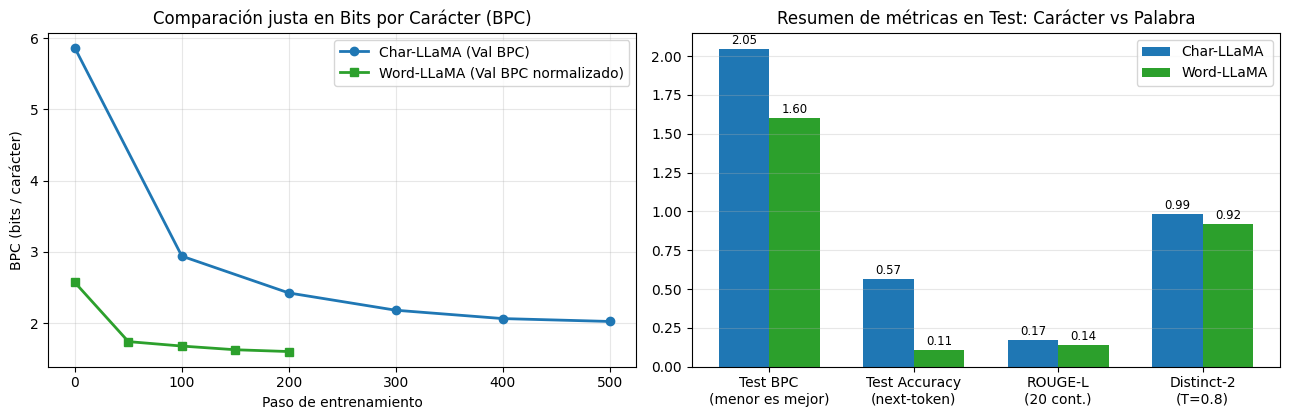

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

c_hist = char_m["history"]
w_hist = word_m["history"]

axes[0].plot(c_hist["step"], c_hist["bpc"], marker="o", linewidth=2, label="Char-LLaMA (Val BPC)", color="#1f77b4")
axes[0].plot(w_hist["step"], w_hist["bpc"], marker="s", linewidth=2, label="Word-LLaMA (Val BPC normalizado)", color="#2ca02c")
axes[0].set_title("Comparación justa en Bits por Carácter (BPC)")
axes[0].set_xlabel("Paso de entrenamiento")
axes[0].set_ylabel("BPC (bits / carácter)")
axes[0].grid(alpha=0.3)
axes[0].legend()

metric_names = ["Test BPC\n(menor es mejor)", "Test Accuracy\n(next-token)", "ROUGE-L\n(20 cont.)", "Distinct-2\n(T=0.8)"]
c_d2 = [r["Distinct-2"] for r in char_m["diversity_by_temp"] if abs(r["Temperatura"] - 0.8) < 1e-4][0]
w_d2 = [r["Distinct-2"] for r in word_m["diversity_by_temp"] if abs(r["Temperatura"] - 0.8) < 1e-4][0]

c_vals = [char_m["test"]["bpc"], char_m["test"]["acc"], char_m["rouge_l_20"], c_d2]
w_vals = [word_m["test"]["bpc"], word_m["test"]["acc"], word_m["rouge_l_20"], w_d2]

x = np.arange(len(metric_names))
width = 0.35
axes[1].bar(x - width / 2, c_vals, width, label="Char-LLaMA", color="#1f77b4")
axes[1].bar(x + width / 2, w_vals, width, label="Word-LLaMA", color="#2ca02c")
axes[1].set_xticks(x)
axes[1].set_xticklabels(metric_names)
axes[1].set_title("Resumen de métricas en Test: Carácter vs Palabra")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()

for i, (cv, wv) in enumerate(zip(c_vals, w_vals)):
    axes[1].text(i - width / 2, cv + 0.03, f"{cv:.2f}", ha="center", fontsize=8.5)
    axes[1].text(i + width / 2, wv + 0.03, f"{wv:.2f}", ha="center", fontsize=8.5)

plt.tight_layout()
plt.savefig("figuras/02_comparativa_char_vs_word.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Análisis cualitativo de modos de fallo (Honestidad experimental)

Comparamos lado a lado qué ocurre cuando cada modelo falla o se enfrenta a entradas difíciles:
1. **Fallo característico del modelo de caracteres (invención morfológica):** nunca produce `<UNK>`, pero cuando una transición de caracteres se desvía a temperatura media-alta ($T \ge 0.8$), concatena sílabas plausibles en inglés que no forman palabras reales.
2. **Fallo característico del modelo de palabras (ceguera ante OOV):** toda palabra real siempre está bien escrita porque sale del diccionario `itos`, pero si el prompt contiene palabras raras o morfología no vista en el millón de caracteres de entrenamiento, las colapsa en `<UNK>`.

In [8]:
tok_char = CharTok(train_text)
rare_prompt = "the telescope magnified the"
unk_ids = tok_word.encode(rare_prompt)
decoded_rare = [tok_word.itos[i] for i in unk_ids]
print("Demostración de fallo OOV en WordTok ante vocabulario fuera de dominio:")
print(f"  Prompt original : {rare_prompt}")
print(f"  Tokens en WordTok: {decoded_rare} (OOV convierte palabras no vistas en <UNK>)")
print(f"  Tokens en CharTok: '{tok_char.decode(tok_char.encode(rare_prompt))}' (0 pérdida de caracteres)\n")

side_by_side = []
for temp in [0.1, 0.5, 0.8, 1.0]:
    s_word = word_samples_df[(word_samples_df["Prompt"] == "once upon a time") & (word_samples_df["Temperatura"] == temp)]["Texto generado (Word-LLaMA)"].iloc[0]
    side_by_side.append({
        "Temperatura": temp,
        "Muestra Word-LLaMA (35 palabras)": s_word,
    })
display(pd.DataFrame(side_by_side))

Demostración de fallo OOV en WordTok ante vocabulario fuera de dominio:
  Prompt original : the telescope magnified the
  Tokens en WordTok: ['the', '<UNK>', '<UNK>', 'the'] (OOV convierte palabras no vistas en <UNK>)
  Tokens en CharTok: 'the telescope magnified the' (0 pérdida de caracteres)



,Temperatura,Muestra Word-LLaMA (35 palabras)
0,0.1,once upon a time a a a a a a a a a a a a a a a...
1,0.5,once upon a time was was a a was a a a a a a w...
2,0.8,once upon a time upon there and there a a a wa...
3,1.0,once upon a time a so a there there a had to t...


## 7. Conclusiones del Punto 2

1. **No comparabilidad de la Perplejidad cruda (`PPL`):** la perplejidad a nivel de palabra es numéricamente mayor que la de carácter porque evalúa incertidumbre sobre un espacio de miles de palabras completas en lugar de unas decenas de letras. Sin embargo, al normalizar mediante **Bits por Carácter (`BPC`)**, el modelo a nivel de palabra logra menor entropía por carácter (`BPC` más bajo), ya que no gasta capacidad en predecir la estructura interna de palabras ya conocidas.
2. **Compromiso de ingeniería:**
   - **Nivel carácter (`CharTok`)** es preferible cuando el texto contiene errores tipográficos, morfología rica o dominios abiertos donde `<UNK>` es inaceptable, pero requiere secuencias ~5 veces más largas y mayor cómputo de atención por oración.
   - **Nivel palabra (`WordTok`)** garantiza ortografía válida en cada paso y genera ~5 veces más texto por evaluación del Transformer, pero infla la tabla de embeddings y pierde información en palabras fuera del vocabulario.
   - Esta evidencia experimental explica por qué los modelos LLaMA de producción adoptan tokenización por **subpalabras (BPE / SentencePiece)** como punto intermedio óptimo entre ambos extremos.